### Code developed by Dorian Marx and Mohammad Amin Eskandari

# Initialization

## Imports

In [ ]:
# Standard Library
import json
from pathlib import Path

# Third-Party Libraries
from nptdms import TdmsFile
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
import tifffile as tiff

# External/Specialized Libraries
import LinOT.auxiliary as aux

# Local Project Modules
import src.gaussian_process_functions as gp
import src.image_analysis as ia
import src.image_visualization as iv
import src.microrheology_analysis_functions as ma
import src.plot_functions as cplt
import src.utility_functions as ut

## Load json file containing dataset information

In [ ]:
# Open and parse the JSON file into a Python dictionary
with open('./dataset.json', 'r', encoding='utf-8') as file:
    dataset_tree = json.load(file)

## Required constants

In [3]:
# Channel indices for the image stack
nuc_ch, actin_ch, pattern_ch, particle_ch = [3, 1, 2, 0] # Map each component to its channel index

# Spatial processing parameters
crop_dim = 650 # Output crop box dimension in pixels
crop_center = crop_dim / 2.0 # Center pixel offset inside crop box (325.0 px)
pixel_size = 0.1083 # Physical camera resolution in micrometers per pixel (um/px)

# Threshold & distance parameters for Gaussian process transformation. Adjust these threshold and distance values to refine anchor point detection.
nuc_dist_th = 3.0       # Nucleus distance threshold (px)
nuc_end_tol = 0         # Nucleus end tolerance (px dilation)
nuc_thresh = 100.0      # Nucleus intensity threshold
actin_thresh = 50.0    # Actin intensity threshold
actin_dist_keep = 100.0  # Actin max distance cutoff (px)

current_ell = 300.0  # Length-scale parameter (ell_input)
zeta = 0.01          # Regularization term
ds_grid = 8          # Grid spacing in pixels
ds_factor = 2.0      # Downsampling factor

## Retrieve required file paths

In [ ]:
# -----------------------------------------------------------------------------
# Base Directories & Metadata Selection
# -----------------------------------------------------------------------------
data_dir = Path("./Example_data/Microrheology")
average_cell_dir = Path("./Example_data/Average_cell")

example_data = dataset_tree["measurements"][0]

# -----------------------------------------------------------------------------
# Data Paths (Active & Passive TDMS)
# -----------------------------------------------------------------------------
active_tdms_path = data_dir / example_data["relative_path"]
passive_tdms_paths = [
    data_dir / p for p in example_data["passive_metadata"]["path_to_passive"]
]

# -----------------------------------------------------------------------------
# Stack Directory & Associated Files
# -----------------------------------------------------------------------------
stack_folder = next(active_tdms_path.parents[2].glob("Stack*"))

raw_max_proj_path = stack_folder / f"{stack_folder.name}_max_proj.tif"
segmented_downsampled_image_path = stack_folder / "Stack_segmented_downsampled.tif"
cell_meta_data_path = stack_folder / "cell_metadata.txt"

# -----------------------------------------------------------------------------
# Reference & Average Cell Template Paths
# -----------------------------------------------------------------------------
pattern_template_path = average_cell_dir / "Pattern_mask.tif"
nucleus_barycenter_path = average_cell_dir / "data_processed/nucleus/nucleus_barycenter.npz"
actin_barycenter_path = average_cell_dir / "data_processed/actin/actin_barycenter.npz"

## Statistics

In [5]:
measurements = dataset_tree.get("measurements", [])

# Collect unique entries using sets
unique_days = set()
unique_cells = set()      # Unique (day, cell) tuples
unique_particles = set()  # Unique (day, cell, particle) tuples

# Track effective physical directions
count_x = 0
count_y = 0

for entry in measurements:
    day = entry.get("day")
    cell = entry.get("cell")
    particle = entry.get("particle")
    direction = entry.get("direction", "").lower()
    is_flipped = entry.get("flipped", False)

    if day is not None:
        unique_days.add(day)

        if cell is not None:
            unique_cells.add((day, cell))

            if particle is not None:
                unique_particles.add((day, cell, particle))

    # Determine true physical direction after accounting for flip/swap
    if direction in ("x", "y"):
        if is_flipped:
            effective_direction = "y" if direction == "x" else "x"
        else:
            effective_direction = direction

        if effective_direction == "x":
            count_x += 1
        elif effective_direction == "y":
            count_y += 1

# Print statistics
print("=" * 40)
print("            DATASET STATS            ")
print("=" * 40)
print(f"Total Active Measurements : {len(measurements)}")
print(f"  ├── Effective X Direction: {count_x}")
print(f"  └── Effective Y Direction: {count_y}")
print(f"Measurement Days          : {len(unique_days)}")
print(f"Total Unique Cells        : {len(unique_cells)}")
print(f"Total Unique Particles    : {len(unique_particles)}")
print("=" * 40)

            DATASET STATS            
Total Active Measurements : 519
  ├── Effective X Direction: 262
  └── Effective Y Direction: 257
Measurement Days          : 16
Total Unique Cells        : 133
Total Unique Particles    : 278


# Microrheology

## 1. Active analysis

In [6]:
# Perform basic analysis on active microrheology TDMS file
active_tdms_file, active_data, active_results, active_signal_ffts = ma.basic_analysis(str(active_tdms_path))

# Extract complex response function χ(f) and complex shear modulus G*(f)
response_function = active_results["chi"]
shear_modulus = active_results["G*"]
storage_modulus = np.real(shear_modulus) # Storage modulus G'(f) [Pa]
loss_modulus = np.imag(shear_modulus) # Loss modulus G''(f) [Pa]
frequencies = active_results.index.to_numpy() # Active driving frequencies [Hz]

# Get physical oscillation axis from TDMS metadata.
# Note: 'x' and 'y' represent optical tweezers coordinates.
# These correspond to micropattern coordinates when micropatterns are vertical,
# but swap when micropatterns are rotated horizontally.
oscillation_direction = "xy"[int(active_tdms_file.groups()[0].properties["x(0)_or_y(1)"])]


## 2. Fit fractional Kelvin-Voigt (fkv) model
$$
G^*(f) = A(2\pi f i)^\alpha + B(2\pi f i)^\beta
$$

A: 39.58 [Pa], B: 0.21 [Pa], alpha: 0.28, beta: 0.93


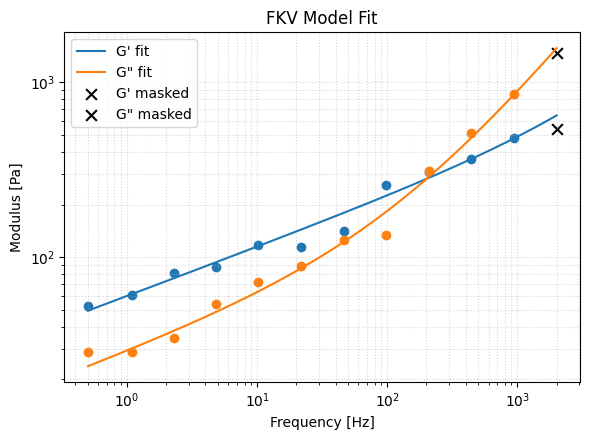

(<Figure size 600x450 with 1 Axes>,
 <Axes: title={'center': 'FKV Model Fit'}, xlabel='Frequency [Hz]', ylabel='Modulus [Pa]'>)

In [7]:
# Load frequency mask indices from json file to exclude noisy/corrupted data points from G* fitting. Provide the list manually if you want to mask other datapoints
masked_indices_g_star = example_data["masked_indices_g_star"]

# Fit the Fractional Kelvin-Voigt (FKV) model to complex viscoelastic moduli (G' and G'')
params, perr, mask = ma.fit_fkv(
    frequencies,
    storage_modulus,
    loss_modulus,
    masked_indices=masked_indices_g_star
)

# Unpack optimal FKV fit parameters: elastic scales (A, B) and power-law exponents (alpha, beta)
A = params[0]
B = params[1]
alpha = params[2]
beta = params[3]

# Display fitted viscoelastic parameters with formatting
print(f"A: {A:4.2f} [Pa], B: {B:4.2f} [Pa], alpha: {alpha:4.2f}, beta: {beta:4.2f}")

# Plot experimental storage and loss moduli against the fitted FKV model curves
cplt.plot_fkv_fit(
    frequencies,
    storage_modulus,
    loss_modulus,
    params,
    masked_indices=masked_indices_g_star,
    title="FKV Model Fit"
)

## 3. Passive analysis

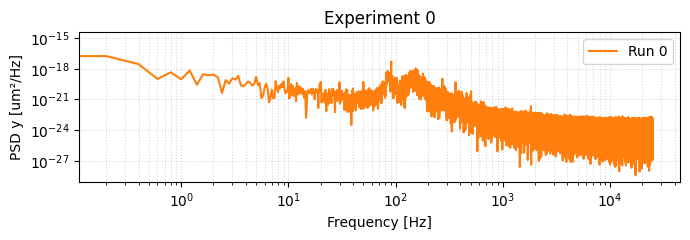

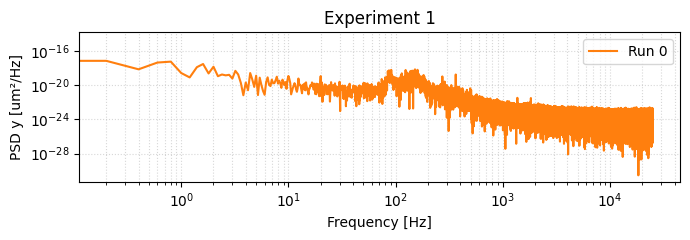

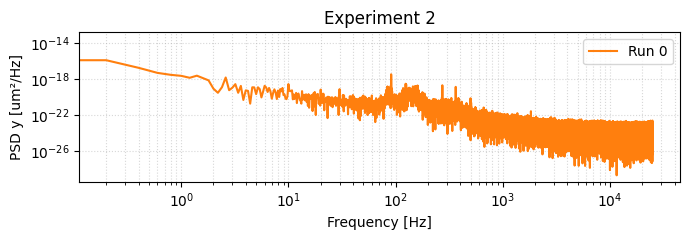

In [8]:
# Iterate through each passive measurement file to perform basic spectral analysis
for i, passive_tdms_path in enumerate(passive_tdms_paths):
    # Analyze raw TDMS files and compute Power Spectral Densities (PSDs)
    passive_tdms_file, pasive_data, passive_psds = ma.basic_analysis(str(passive_tdms_path))

    # plot the calculated power spectral density
    cplt.plot_passive_psds(passive_psds, title=f"Experiment {i}")

## 4. Effective energy
$$
E_{eff}(f) = Ef^\gamma
$$

Masked frequencies: [ 97.96120146 208.18005453 442.70568878]
Fit succeeded with status 2: `ftol` termination condition is satisfied.
Masked frequencies: [ 97.96120146 208.18005453 442.70568878]
Fit succeeded with status 2: `ftol` termination condition is satisfied.


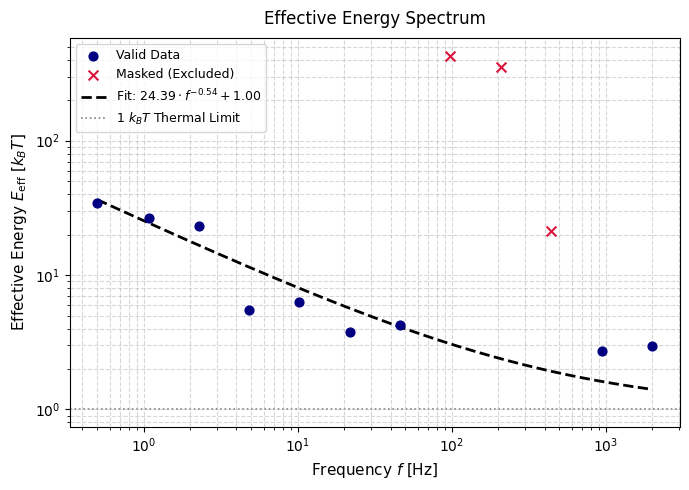

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Effective Energy Spectrum'}, xlabel='Frequency $f$ [Hz]', ylabel='Effective Energy $E_{\\mathrm{eff}}$ [$k_B T$]'>)

In [10]:
passive_psd = 0
passive_num = 0

# Extract valid trial indices per passive run from JSON metadata.
# Note: To analyze custom/additional trials, supply a manual list of trial indices for all passive measurements you want to analyze.
passive_trials_per_run = example_data["passive_metadata"]["trials_per_run"]
trial_lists = list(passive_trials_per_run.values())


# Compute the average Power Spectral Density (PSD) across all valid passive measurements for the particle.
# Note: File paths are retrieved from JSON. To include other passive measurements, provide a custom list of paths.
for i, passive_tdms_path in enumerate(passive_tdms_paths):
    passive_tdms_file, pasive_data, passive_psds = ma.basic_analysis(str(passive_tdms_path))
    for j in trial_lists[i]:
        passive_psd += passive_psds[j]["psd_y"]
        passive_num += 1
    passive_freqs = passive_psds[0]["freq"]

passive_psd /= passive_num

# Load raw active microrheology dataset
active_tdms_file, active_data, active_results, active_signal_ffts = ma.basic_analysis(str(active_tdms_path))

active_response_function = active_results["chi"]  # Measured complex response function
active_freqs = active_results.index.to_numpy()     # Active driving frequencies

# Bin the full-resolution passive PSD at the active driving frequencies
passive_freq_bin, passive_psd_bin = ma.bin_psd_log(
    passive_freqs,
    passive_psd,
    active_freqs,
    exclude_range=None
)

# Compute initial effective energy E_eff by comparing active and passive spectra
e_eff = ma.effective_energy(
    passive_freq_bin,
    passive_psd_bin,
    active_response_function
)

# Load frequency mask indices to exclude instrumental noise. This is retrieved from JSON. If you want to have other indices masked, provide a custom list.
excluded_idx = example_data["masked_indices_e_eff"]

# Fit power-law model to initial effective energy spectrum
fit_params, fit_errors, _ = ma.fit_e_eff(
    f=passive_freq_bin,
    e_eff=e_eff,
    p0=(1.0, -1.0, passive_psd_bin[-1]),
    masked_indices=excluded_idx,
    force_one_kbt=False
)

# Physical Calibration: High-frequency activity must converge to thermal noise (E_eff -> 1 k_B T).
# If high-frequency offset (fit_params[2]) is non-zero, normalize the passive PSD against it.
# Passive PSD is rescaled rather than active response because active optical trap measurements offer higher SNR and accuracy.
if fit_params[2] > 0.01:
    passive_psd_bin /= fit_params[2]
else:
    passive_psd_bin /= np.exp((np.log(passive_psd_bin[-1]) + np.log(passive_psd_bin[-2])) / 2)

# Re-calculate effective energy spectrum using calibrated passive PSD
e_eff = ma.effective_energy(
    frequencies=passive_freq_bin,
    psd=passive_psd_bin,
    res_func=active_response_function
)

# Refit power-law model to recalibrated effective energy spectrum
fit_params, fit_errors, _ = ma.fit_e_eff(
    f=passive_freq_bin,
    e_eff=e_eff,
    p0=(1.0, -1.0, passive_psd_bin[-1]),
    masked_indices=excluded_idx,
    force_one_kbt=False
)

cplt.plot_effective_energy(
    frequencies=passive_freq_bin,
    e_eff=e_eff,
    fit_params=fit_params,
    masked_indices=excluded_idx
)

# Locating the microprobe relative to micropattern

## 1. Extracting Stage Metadata
* **Cell Acquisition:** Motor and piezo positions during image capture
* **Particle Measurement:** Motor and piezo positions during particle capture

In [11]:

# Read cell stage positioning metadata from text file
txt_file = stack_folder / f"{stack_folder.name}.txt" # Path to stage metadata text file
with open(txt_file, "r") as f: # Open metadata text file in read mode
    lines = f.readlines() # Read all lines into list
    h_keys = [x.strip() for x in lines[0].split(',')] # Extract and clean header keys
    v_vals = [x.strip() for x in lines[1].split(',')] # Extract and clean header values
    p_dict = dict(zip(h_keys, v_vals)) # Map header keys to values in dictionary

# Extract cell stage positions into numpy arrays
cell_motor = np.array([float(p_dict['Motor Stage Position X (um)']), float(p_dict['Motor Stage Position Y (um)'])]) # Cell motor stage [X, Y] in um
cell_piezo = np.array([float(p_dict['Piezo Stage Position X (um)']), float(p_dict['Piezo Stage Position Y (um)'])]) # Cell piezo stage [X, Y] in um

# Read particle stage positioning metadata from TDMS properties
tdms = TdmsFile.read(active_tdms_path) # Read TDMS file into object
props = tdms.groups()[0].properties # Extract group property dictionary
part_motor = np.array([float(x) for x in props["Motor stage positions x;y (um)"].split(';')]) # Particle motor stage [X, Y] in um
part_piezo = np.array([float(x) for x in props["Piezo positions x;y;z (um)"].split(';') if x])[:2] # Particle piezo stage [X, Y] in um

# Print formatted summary comparing cell and particle stage positions
ut.print_cell_particle_data( # Call summary printer utility
    cell_txt_path=txt_file, # Pass cell text file path
    particle_tdms_path=active_tdms_path, # Pass particle TDMS path
    cell_motor=cell_motor, # Pass cell motor position
    part_motor=part_motor, # Pass particle motor position
    cell_piezo=cell_piezo, # Pass cell piezo position
    part_piezo=part_piezo # Pass particle piezo position
) # End printer call

════════════════════════════════════════════════════════════════════════════════════════════════════════
                                            METADATA SUMMARY                                            
════════════════════════════════════════════════════════════════════════════════════════════════════════
  Parameter                    │ Cell (Stack_ position 32_0001.txt)  │ Particle (Active_microrheology.tdms)
────────────────────────────────────────────────────────────────────────────────────────────────────────
  Motor (X, Y) [um]            │        [-1145.40, -1781.20]         │        [-1145.40, -1781.20]        
  Piezo (X, Y) [um]            │            [0.00, 0.00]             │            [0.16, 0.99]            
════════════════════════════════════════════════════════════════════════════════════════════════════════


## 2. Image Alignment & Pattern Cropping
* **Rotation:** Align multichannel stack to standard grid angle
* **Pattern Detection:** Find micropattern centroid using template matching
* **Multichannel Cropping:** Crop all channels centered on detected pattern centroid

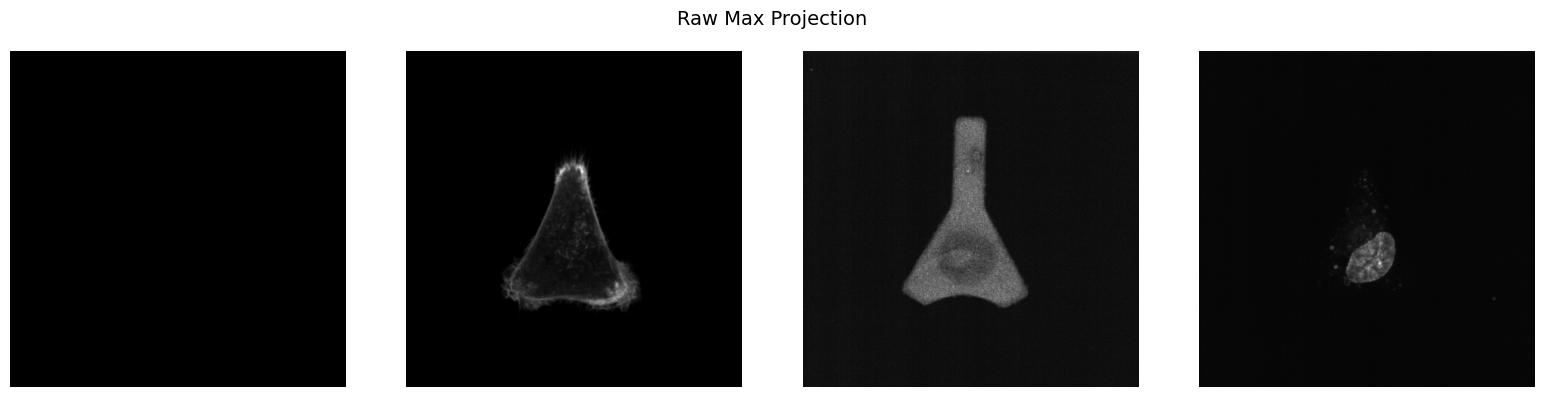

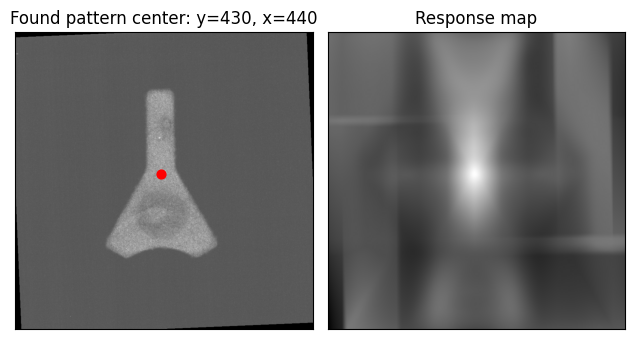

Pattern center (cell_pixel_position_y and cell_pixel_position_x in cell_metadata.txt):
 (430, 440)


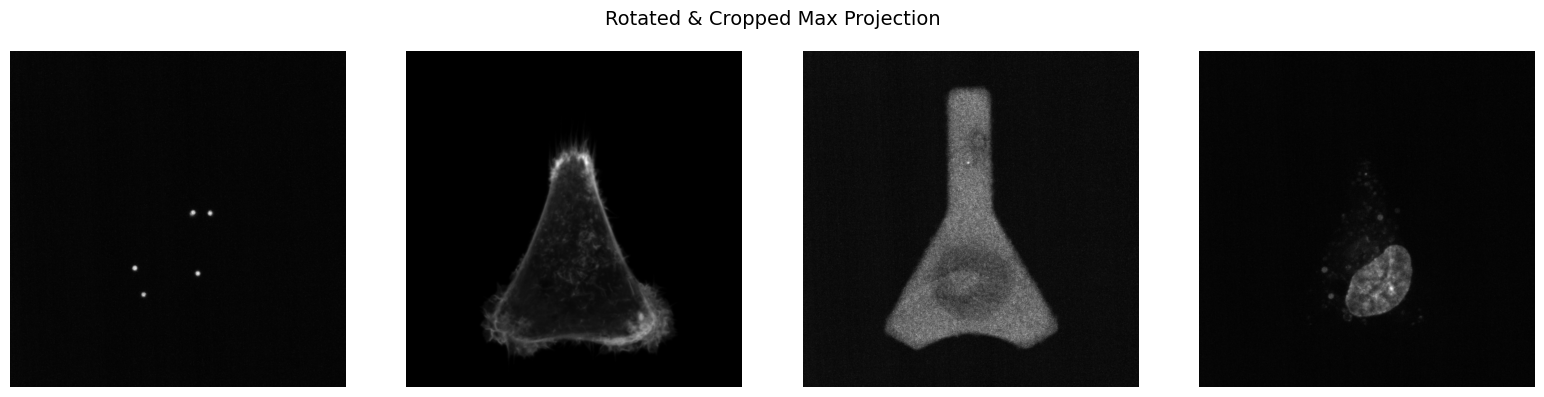

In [12]:
# Load raw image stack and pattern template
raw_max_proj = tiff.imread(str(raw_max_proj_path)).astype(np.float32) # Load raw image stack (C, Y, X) as float32
iv.show_multichannel(raw_max_proj, title="Raw Max Projection") # Display raw image channels

pattern_template = tiff.imread(str(pattern_template_path)).astype(np.float32) # Load pattern mask template as float32

# Ingest alignment metadata from text file
rotation_angle = None # Initialize rotation angle variable
raw_img_center_x = None # Initialize image center X variable
raw_img_center_y = None # Initialize image center Y variable

with open(cell_meta_data_path, "r", encoding="utf-8") as f: # Open cell metadata file
    for line in f: # Iterate through each line
        if ":" in line: # Check for key-value pair delimiter
            key, val = line.split(":", 1) # Split line into key and value
            key = key.strip() # Strip whitespace from key
            val = float(val.strip()) # Convert value to float

            if key == "rotation_angle": # Match rotation angle key
                rotation_angle = val # Store rotation angle
            elif key == "raw_img_center_x": # Match raw center X key
                raw_img_center_x = val # Store center X pixel
            elif key == "raw_img_center_y": # Match raw center Y key
                raw_img_center_y = val # Store center Y pixel

# Combine image center into 2D array [Y, X]
raw_img_center = np.array([raw_img_center_y, raw_img_center_x], dtype=np.float32) # Store center as [Y, X] for image indexing

# Rotate all channels on GPU
ch_count = raw_max_proj.shape[0] # Get total channel count (C)
rotated_max_proj = np.zeros_like(raw_max_proj) # Allocate array for rotated images
for c in range(ch_count): # Loop through each channel
    rotated_max_proj[c] = ia.rotate_2d_cupy(raw_max_proj[c], rotation_angle) # Rotate 2D channel slice on GPU

# Locate pattern center using normalized cross-correlation (NCC)
best_coords, cropped_pattern, _ = ia.find_pattern_centroid_ncc_2d( # Find matching pattern center
    rotated_max_proj[pattern_ch], pattern_template, crop_size=(crop_dim, crop_dim), show=True # Input pattern channel, template, crop size, and show flag
) # Returns best_coords (Y, X), cropped pattern slice, and response map
print(f"Pattern center (cell_pixel_position_y and cell_pixel_position_x in cell_metadata.txt):\n {best_coords}") # Print pattern center

# Crop all channels centered on detected pattern center
transformed_image = np.zeros((ch_count, crop_dim, crop_dim), dtype=np.float32) # Allocate output cropped stack (C, 650, 650)
transformed_image[pattern_ch] = cropped_pattern # Insert pre-cropped pattern channel slice

for c in range(ch_count): # Iterate through all channels
    if c != pattern_ch: # Skip pattern channel
        transformed_image[c] = ia.crop_and_pad_2d( # Crop and pad remaining channels
            rotated_max_proj[c], best_coords, (crop_dim, crop_dim) # Input rotated channel, pattern center (Y, X), and crop box size
        ) # Place cropped slice into transformed array

# Display rotated and cropped channels side-by-side
iv.show_multichannel(transformed_image, title="Rotated & Cropped Max Projection") # Visualize transformed channels

## 3. Mapping Particle Coordinates Relative to the Micropattern

* **Stage Offset Math:** Calculate net piezo-motor stage difference between cell and particle acquisitions
* **Raw Pixel Projection:** Map physical stage displacement ($\mu\text{m}$) onto raw image pixel coordinates
* **Coordinate Rotation:** Rotate particle location around raw image center by the alignment angle
* **Pattern Frame Alignment:** Compute particle pixel coordinates and physical offsets ($\mu\text{m}$) inside the cropped pattern frame

═══════════════════════════════════════════════════════
              PARTICLE TRANSFORM SUMMARY               
═══════════════════════════════════════════════════════
  Metric                         │         Value         
───────────────────────────────────────────────────────
  Raw Particle (X, Y)            │    (446.03, 456.64)   
  Rotated Particle (X, Y)        │    (446.42, 456.69)   
  Raw Center (X, Y)              │    (447.50, 447.50)   
  Pattern Center (X, Y)          │    (440.00, 430.00)   
  In-Crop Particle (X, Y)        │    (331.42, 351.69)   
  Relative Offset (X, Y) [um]    │    (0.695, -2.891)    
═══════════════════════════════════════════════════════


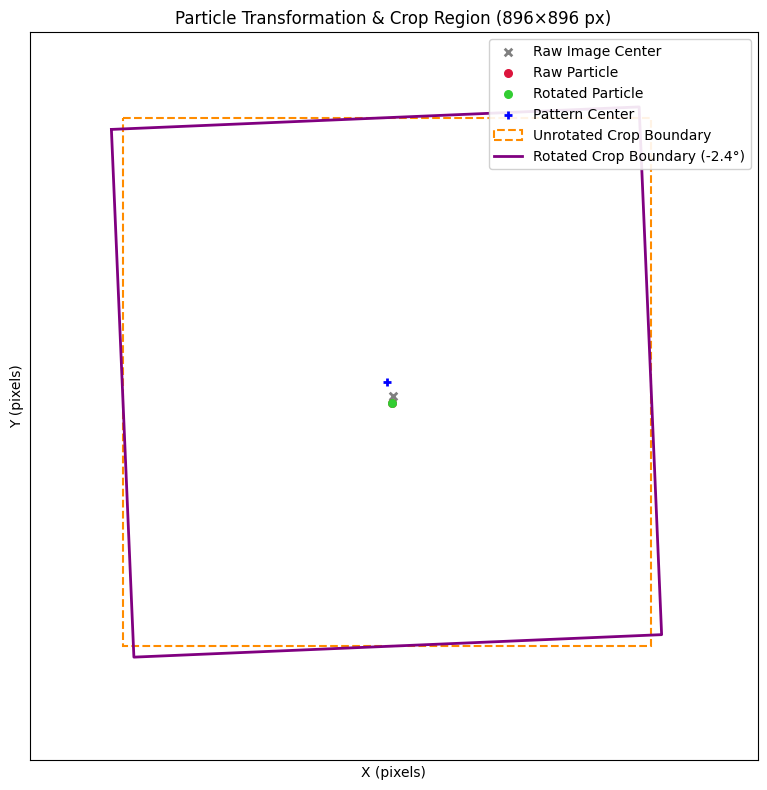

In [13]:
# Calculate net piezo vs motor stage offsets in micrometers
particle_diff = part_piezo - part_motor # Net particle stage offset [dX, dY] in um
cell_diff = cell_piezo - cell_motor # Net cell stage offset [dX, dY] in um

# Compute particle offset relative to cell center in micrometers
part_rel_center_um = particle_diff - cell_diff # Relative stage offset in um
part_rel_center_um[1] = -part_rel_center_um[1] # Invert Y for image coordinate space

# Map physical offset (um) to raw unrotated pixel coordinates [X, Y]
particle_px_raw = -part_rel_center_um / pixel_size + np.array([raw_img_center[1], raw_img_center[0]]) # Convert offset to pixels and add image center

# Rotate particle point around raw image center
theta = np.radians(rotation_angle) # Convert angle to radians
v_x = particle_px_raw[0] - raw_img_center[1] # Unrotated X offset from raw image center
v_y = particle_px_raw[1] - raw_img_center[0] # Unrotated Y offset from raw image center

v_x_rot = v_x * np.cos(theta) - v_y * np.sin(theta) # Rotated X offset from center
v_y_rot = v_x * np.sin(theta) + v_y * np.cos(theta) # Rotated Y offset from center

p_full_rot_x = raw_img_center[1] + v_x_rot # Rotated particle full-frame X coordinate
p_full_rot_y = raw_img_center[0] + v_y_rot # Rotated particle full-frame Y coordinate

# Compute offsets relative to detected pattern center
dx_from_pattern = p_full_rot_x - best_coords[1] # Particle X offset from pattern center in px
dy_from_pattern = p_full_rot_y - best_coords[0] # Particle Y offset from pattern center in px

# Compute final particle coordinates inside local 650x650 crop box
abs_px_x = crop_center + dx_from_pattern # In-crop particle X coordinate (325 + dx)
abs_px_y = crop_center + dy_from_pattern # In-crop particle Y coordinate (325 + dy)

# Convert relative pattern offsets to physical units (um)
rel_x_um = dx_from_pattern * pixel_size # Relative X offset in um
rel_y_um = -dy_from_pattern * pixel_size # Relative Y offset in um

# Summarize metrics and plot transformed coordinates on full-frame plot
ut.summarize_and_plot_particle_transform(
    particle_px_raw=particle_px_raw,
    p_full_rot_x=p_full_rot_x,
    p_full_rot_y=p_full_rot_y,
    raw_img_center=raw_img_center,
    best_coords=best_coords,
    rotation_angle=rotation_angle,
    raw_img_shape=raw_max_proj.shape[1:],
    crop_dim=crop_dim,
    rel_x_um=rel_x_um,
    rel_y_um=rel_y_um,
)

# Single-Cell to Average-Cell Coordinate Mapping

## 1. Calcualte Tangent Vectors

In [14]:
nucleus_reference_image = np.load(nucleus_barycenter_path)["barycenter"]
actin_reference_image = np.load(actin_barycenter_path)["barycenter"]

nucleus_mass_ref, nucleus_pos_ref = aux.processDensity_Grid(nucleus_reference_image, totalMass=1.0, keepZero=False)

# Load downsampled multichannel stack (C, Y, X).
segmented_image = tiff.imread(str(segmented_downsampled_image_path))

nucleus_sample_slice = segmented_image[nuc_ch]
actin_sample_slice = segmented_image[actin_ch]

# Calculate and save Nucleus Tangent Vectors
print("Calculating Nucleus Tangent Vectors (please wait)...")
nucleus_sample_density = [aux.processDensity_Grid(nucleus_sample_slice, totalMass=1.0, keepZero=False)]
nucleus_tangent_vectors = gp.compute_linot_tangent(nucleus_sample_density, nucleus_pos_ref, nucleus_mass_ref)

print(f"\nTangent vector calculation completed for Stack: {stack_folder.name}")

Calculating Nucleus Tangent Vectors (please wait)...

Tangent vector calculation completed for Stack: Stack_ position 32_0001


## 2. Find anchor points

### Nucleus anchors

Found 183 Nucleus anchor points.


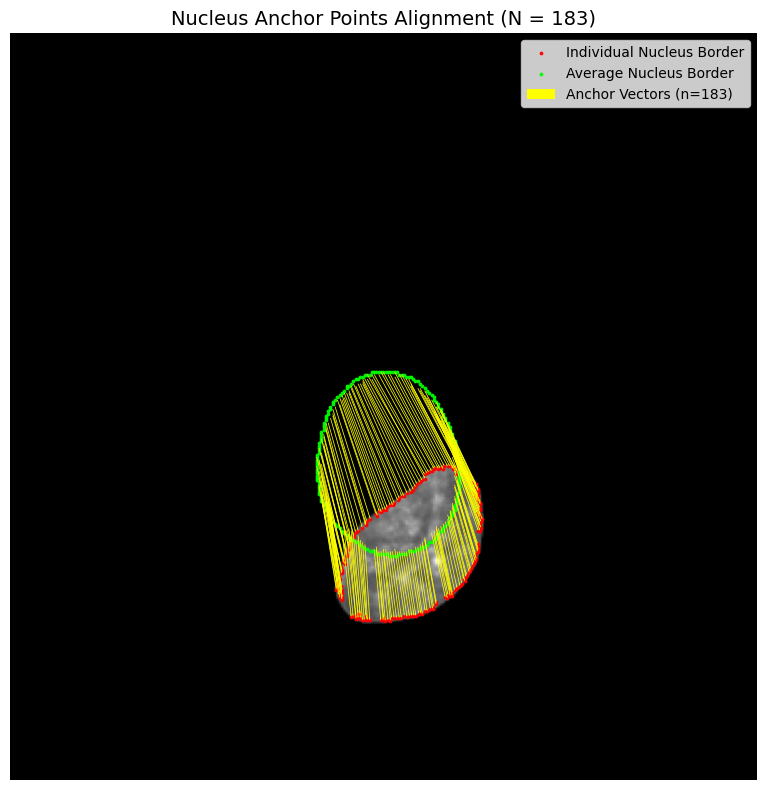

In [15]:
# --- Extract Borders ---
n_nucleus_ch = 255.0 * nucleus_sample_slice / np.max(nucleus_sample_slice)
mask_sample = (n_nucleus_ch > nuc_thresh)
mask_avg = (nucleus_reference_image > np.max(nucleus_reference_image) / 20.0)

border_sample = mask_sample ^ ndi.binary_erosion(mask_sample)
border_avg = mask_avg ^ ndi.binary_erosion(mask_avg)

# --- Match Sample & Reference Borders ---
by_avg, bx_avg = np.where(border_avg)
tree = cKDTree(np.column_stack((bx_avg, by_avg)))

X_nuc, Y_nuc = nucleus_pos_ref[:, 1], nucleus_pos_ref[:, 0]
U_nuc, V_nuc = nucleus_tangent_vectors[:, 1], nucleus_tangent_vectors[:, 0]

h, w = mask_sample.shape
X_start = np.clip(np.round(X_nuc).astype(int), 0, w - 1)
Y_start = np.clip(np.round(Y_nuc).astype(int), 0, h - 1)

start_points = np.column_stack((X_start, Y_start))
dists_to_avg_border, _ = tree.query(start_points, k=1)

X_end = np.clip(np.round(X_nuc + U_nuc).astype(int), 0, w - 1)
Y_end = np.clip(np.round(Y_nuc + V_nuc).astype(int), 0, h - 1)

if nuc_end_tol == 0:
    ends_on_border = border_sample[Y_end, X_end]
else:
    struct = ndi.generate_binary_structure(2, 1)
    dilated_border = ndi.binary_dilation(border_sample, structure=struct, iterations=nuc_end_tol)
    ends_on_border = dilated_border[Y_end, X_end]

valid_indices = np.nonzero(ends_on_border)[0]

X_end_v = X_end[valid_indices]
Y_end_v = Y_end[valid_indices]
X_nuc_v = X_nuc[valid_indices]
Y_nuc_v = Y_nuc[valid_indices]
U_v = U_nuc[valid_indices]
V_v = V_nuc[valid_indices]
dists_v = dists_to_avg_border[valid_indices]

# Resolve multiple hits per pixel
best_for_end = {}
for idx_local, (y_end_val, x_end_val, dist_val) in enumerate(zip(Y_end_v, X_end_v, dists_v)):
    key = f"{y_end_val}_{x_end_val}"
    if key not in best_for_end or dist_val < best_for_end[key][0]:
        best_for_end[key] = (dist_val, idx_local)

selected_local_indices = [v[1] for v in best_for_end.values()]

X_selected = X_nuc_v[selected_local_indices]
Y_selected = Y_nuc_v[selected_local_indices]
U_selected = U_v[selected_local_indices]
V_selected = V_v[selected_local_indices]
dists_selected = dists_v[selected_local_indices]

close_mask = dists_selected < nuc_dist_th

# --- Final Anchor Point Arrays ---
nuc_anchor_x = X_selected[close_mask]
nuc_anchor_y = Y_selected[close_mask]
nuc_anchor_u = U_selected[close_mask]
nuc_anchor_v = V_selected[close_mask]

print(f"Found {len(nuc_anchor_x)} Nucleus anchor points.")
# Visualize Nucleus Anchors
iv.plot_nucleus_anchor_points(
    nucleus_sample_slice=nucleus_sample_slice,
    nucleus_reference_image=nucleus_reference_image,
    nuc_anchor_x=nuc_anchor_x,
    nuc_anchor_y=nuc_anchor_y,
    nuc_anchor_u=nuc_anchor_u,
    nuc_anchor_v=nuc_anchor_v,
    nuc_thresh=nuc_thresh
)

### Actin anchors

Found 668 Actin anchor points.


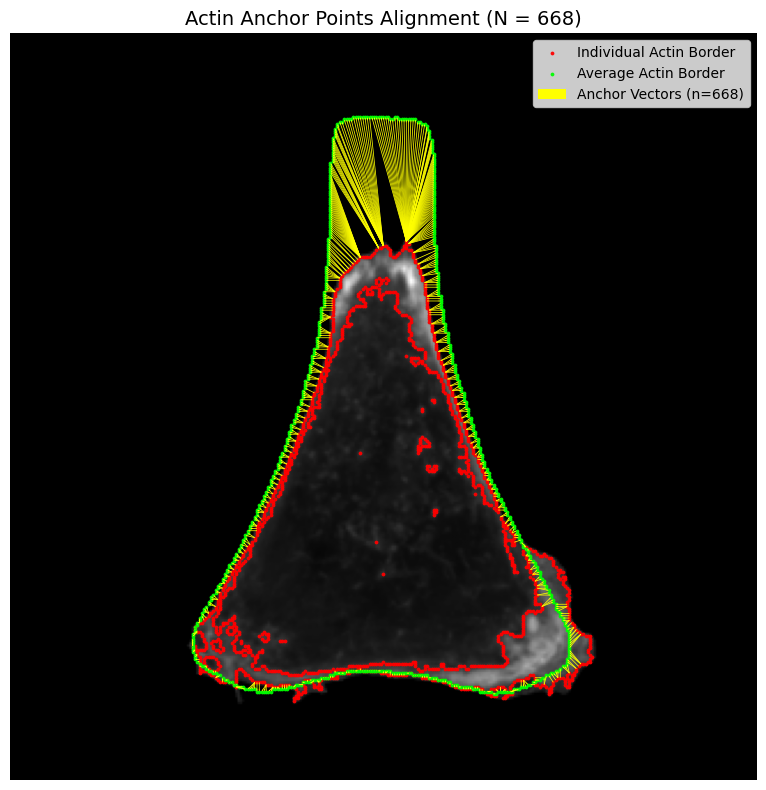

In [16]:
# --- Extract Borders ---
n_actin_ch = 255.0 * actin_sample_slice / np.max(actin_sample_slice)

mask_sample = (n_actin_ch > actin_thresh)
mask_avg = ndi.binary_erosion((actin_reference_image > 0), iterations=5)

border_sample = mask_sample ^ ndi.binary_erosion(mask_sample)
border_avg = mask_avg ^ ndi.binary_erosion(mask_avg)

by_avg, bx_avg = np.where(border_avg)
by_smp, bx_smp = np.where(border_sample)

# --- Find Nearest Neighbors via KDTree ---
tree_sample = cKDTree(np.column_stack((bx_smp, by_smp)))
avg_points = np.column_stack((bx_avg, by_avg))
dists, idx_nearest = tree_sample.query(avg_points, k=1)

X_end, Y_end = avg_points[:, 0], avg_points[:, 1]
X_start, Y_start = bx_smp[idx_nearest], by_smp[idx_nearest]

keep = dists < actin_dist_keep

# --- Final Anchor Point Arrays ---
actin_anchor_x = X_start[keep]
actin_anchor_y = Y_start[keep]
actin_anchor_u = X_end[keep] - X_start[keep]
actin_anchor_v = Y_end[keep] - Y_start[keep]

print(f"Found {len(actin_anchor_x)} Actin anchor points.")
# Visualize Actin Anchors
iv.plot_actin_anchor_points(
    actin_sample_slice=actin_sample_slice,
    actin_reference_image=actin_reference_image,
    actin_anchor_x=actin_anchor_x,
    actin_anchor_y=actin_anchor_y,
    actin_anchor_u=actin_anchor_u,
    actin_anchor_v=actin_anchor_v,
    actin_thresh=actin_thresh
)

## 3. Transform Coordinates

Grid Deformed using 851 combined anchor points.
Transformed Particle Position in Average Cell Frame: (152.01, 147.90)


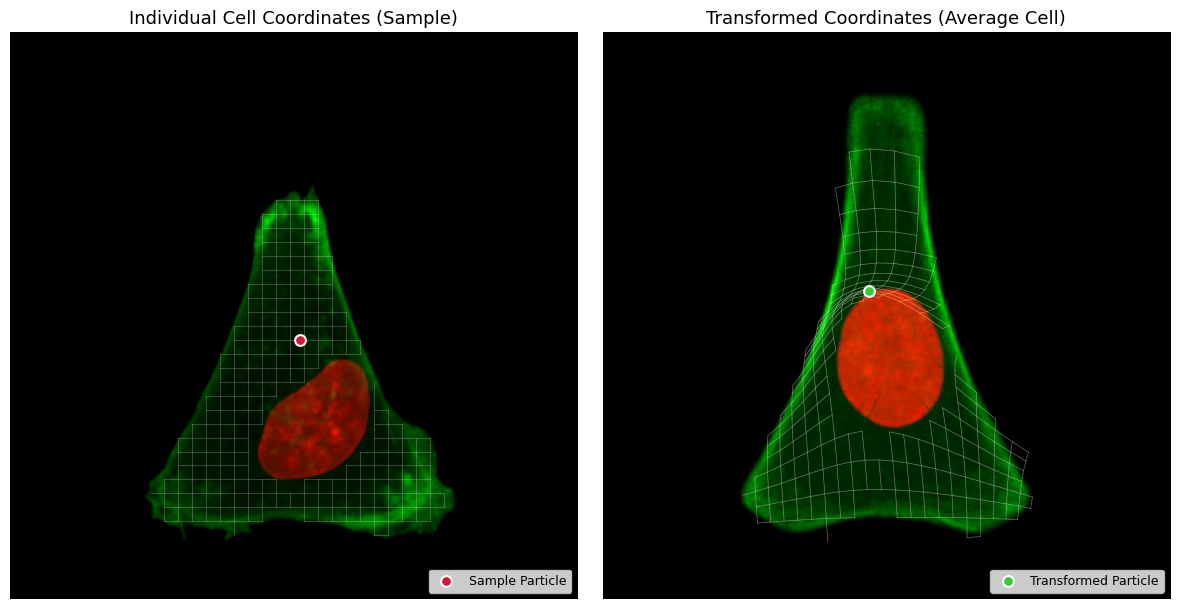

In [17]:
act_sample_pts = np.column_stack((actin_anchor_x, actin_anchor_y))
act_target_pts = np.column_stack((actin_anchor_x + actin_anchor_u, actin_anchor_y + actin_anchor_v))

nuc_sample_pts = np.column_stack((nuc_anchor_x + nuc_anchor_u, nuc_anchor_y + nuc_anchor_v))
nuc_target_pts = np.column_stack((nuc_anchor_x, nuc_anchor_y))

train_start = np.vstack([act_sample_pts, nuc_sample_pts])  # Source points
train_end   = np.vstack([act_target_pts, nuc_target_pts])  # Target points


# --- 3. Deform Pixel Grid across Image Frame ---
H, W = nucleus_reference_image.shape
X, Y = np.meshgrid(np.arange(0, W, ds_grid), np.arange(0, H, ds_grid))
grid_pos_vec = np.column_stack([X.ravel(), Y.ravel()])

# Apply Matérn transformation to regular grid
grid_pos_transformed = gp.transform_r_vec(
    grid_pos_vec, train_start, train_end, ell=current_ell, zeta=zeta
)

Xnew = grid_pos_transformed[:, 0].reshape(X.shape)
Ynew = grid_pos_transformed[:, 1].reshape(Y.shape)


# --- 4. Map Particle Coordinates to Average Cell Space ---
# particle_absolute_pixel_x/y_in_cropped_frame are from section 4 mapping
particle_sample_pixel_xy = np.array([[abs_px_x / ds_factor, abs_px_y / ds_factor]], dtype=np.float64)

particle_transformed_xy = gp.transform_r_vec(
    particle_sample_pixel_xy, train_start, train_end, ell=current_ell, zeta=zeta
)

p_trans_x = particle_transformed_xy[0, 0]
p_trans_y = particle_transformed_xy[0, 1]

print(f"Grid Deformed using {len(train_start)} combined anchor points.")
print(f"Transformed Particle Position in Average Cell Frame: ({p_trans_x:.2f}, {p_trans_y:.2f})")



iv.plot_transformation_results(
    segmented_sample_stack=segmented_image,
    nucleus_reference=nucleus_reference_image,
    actin_reference=actin_reference_image,
    nuc_anchors_tuple=(nuc_anchor_x, nuc_anchor_y, nuc_anchor_u, nuc_anchor_v),
    act_anchors_tuple=(actin_anchor_x, actin_anchor_y, actin_anchor_u, actin_anchor_v),
    Xnew=Xnew,
    Ynew=Ynew,
    sample_particle_xy=(abs_px_x / ds_factor, abs_px_y / ds_factor),
    transformed_particle_xy=(p_trans_x, p_trans_y),
    nuc_ch_ix=nuc_ch,
    actin_ch_ix=actin_ch,
    ds_grid=ds_grid,
)